# CNN Detector — Development Log

**What this is.** The story of the deep-learning detector: what we tried, what we found, and what
we ruled out. Written so that in six months it explains not just *what the numbers were* but *why
each experiment was shaped the way it was* — including the readings we got wrong and retracted.

**How to read it.** Chronological, one section per experiment, each with the same five headings:
the question · the setup · the results · what it showed · what it changed.

**How to extend it.** Add a new section in the same format at the end of the experiment list, using
the template in `scripts/build_cnn_log_notebook.py`, then re-run that script. Results are computed
from saved artefacts in `results/`, not pasted in, so re-running refreshes them.

**Scope.** This file covers the *network*. Milestone-numbered background — the radar re-spec, the
CFAR window selection, the data-quality audit, the clutter-edge investigation — lives in
`PROGRESS.md` and is cross-referenced rather than repeated.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DL = ROOT / "results" / "dl"

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
TRAIN, VAL, DLC, CFARC = "#2a78d6", "#eb6834", "#2a78d6", "#898781"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
                     "axes.grid": True, "grid.alpha": 0.6, "figure.dpi": 120})

def history(tag):
    p = DL / f"history_{tag}.json"
    return pd.DataFrame(json.load(open(p))) if p.exists() else None

# Cumulative archive of every checkpoint ever scored (see scripts/compare_checkpoints.py).
HIST = pd.read_csv(DL / "checkpoint_history.csv") if (DL / "checkpoint_history.csv").exists() else None

# CFAR on the SAME split, for every comparison below.
CFAR_VAL = pd.read_csv(ROOT / "results" / "cfar_val" / "summary.csv")
CFAR_BEST = (CFAR_VAL.dropna(subset=["pd"]).loc[CFAR_VAL.dropna(subset=["pd"])
             .groupby("condition").pd.idxmax()][["condition", "method", "pd"]]
             .set_index("condition"))
print("CFAR best per condition on bench2_val:")
print(CFAR_BEST.round(3).to_string())

CFAR best per condition on bench2_val:
             method     pd
condition                 
clutter          GO  0.149
clutter_edge     OS  0.443
isolated         CA  0.710
masking          OS  0.645
mixed            GO  0.426
multi            CA  0.680
unresolved       CA  0.485


---
## Standing decisions, and why

These constrain every experiment below. They were each forced by a specific finding, so the reason
is recorded with the rule.

**1 — `bench2_val` for every comparison while choices are still open. `bench2_test` stays
untouched.** The test split was measured once for the pre-registered CFAR baseline (`PROGRESS.md`
Milestone 21) and is not read again until the configuration is locked. The cost is a wider noise
floor — 200 frames per condition against test's 400 — and that is the right price for keeping the
reported numbers uncontaminated by the choices we are still making.

**2 — Validation loss is not a stopping signal here.** It plateaued from ~epoch 26 while Pd on the
clutter-bearing conditions *appeared* to still be moving. Loss is a proxy; the reported metric is Pd
at matched measured Pfa, and when the two disagreed we followed Pd. (The apparent movement later
turned out to be seed noise — see Corrections — but the principle stands: the proxy and the metric
disagreed, so the proxy lost.)

**3 — Single-seed results are not trusted.** The noise floor must be known before any comparison is
believed. One trajectory cannot separate "the model changed" from "the evaluation is noisy"; only
varying the seed can.

**4 — Loss values are not comparable across `pos_weight` values.** The loss scale is set by
`pos_weight × positive_rate`. Only Pd at matched measured Pfa is comparable across configurations.

**5 — Operating point is always matched *measured* Pfa**, swept per condition, never design Pfa.
Rationale in `PROGRESS.md` step 5: clutter drives achieved rates 60–125× above design, by different
factors per method.

---
## 1 · Initial runs — 12 epochs (old sensor) and 50 epochs (current)

### Question
Does the pipeline work end to end, and where does training stop improving?

### Setup
| | 12-epoch run | 50-epoch run |
|---|---|---|
| when | 2026-07-31 | 2026-08-11 |
| sensor | old 256×128 | current 256×64 (CARRADA-matched) |
| data | `bench_train` 9,600 | `bench2_train` **8,400 (all)** |
| val | 800 of 1,600 | **1,600 (all)** |
| epochs | 12, fixed | 50, no early stopping |
| `pos_weight` | 200 | 974 |
| command | notebook, since deleted (`14b38bd`) | `python scripts/train_tinycnn.py --epochs 50 --tag bench` |

The 12-epoch run's numbers do not carry over — different sensor, different class ratio, and it had
three defects fixed since: it stopped at a fixed epoch count with val loss *still falling*, kept the
last epoch rather than the best, and used half the validation set.

The 50-epoch run also rebuilt the infrastructure: a script instead of a notebook (a run is now a
command with a recorded config), a pre-normalised cache (reading 8,400 `.npy` files cost 325 s/epoch
against 89 s of compute), and seeded determinism — later **verified** when a 30-epoch re-run
reproduced epochs 27–30 of the original to all five decimals.

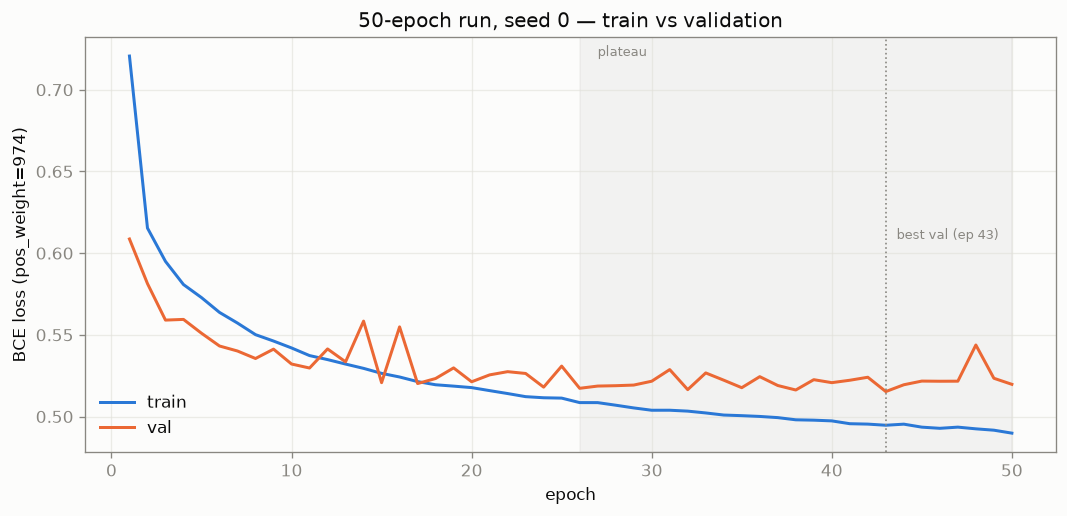

best val 0.51529 at epoch 43;  last 0.51971 at 50
train 0.72061 -> 0.48984


In [2]:
h = history("bench")
if h is not None:
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.plot(h.epoch, h.train_loss, color=TRAIN, lw=1.8, label="train")
    ax.plot(h.epoch, h.val_loss, color=VAL, lw=1.8, label="val")
    b = int(h.val_loss.idxmin()) + 1
    ax.axvline(b, color=MUTED, ls=":", lw=1)
    ax.text(b + 0.6, h.val_loss.max(), f"best val (ep {b})", fontsize=8, color=MUTED)
    ax.axvspan(26, 50, color=MUTED, alpha=0.08)
    ax.text(27, h.train_loss.max(), "plateau", fontsize=8, color=MUTED)
    ax.set_xlabel("epoch"); ax.set_ylabel(f"BCE loss (pos_weight=974)")
    ax.set_title("50-epoch run, seed 0 — train vs validation")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"best val {h.val_loss.min():.5f} at epoch {b};  last {h.val_loss.iloc[-1]:.5f} at 50")
    print(f"train {h.train_loss.iloc[0]:.5f} -> {h.train_loss.iloc[-1]:.5f}")

### What it showed
Gates all passed: receptive field measured **21×9** (matching the CFAR window, which is what makes
this a controlled experiment — see `PROGRESS.md` Milestone 13), overfit-one-batch collapsed 1370×
with 17/17 peaks within 1 bin, cache byte-identical to reading frames individually.

Best val 0.51529 at epoch 43, last 0.51971 at 50. Train kept falling throughout.

### What it changed
Nothing yet — the stopping question moved to the trend analysis below.

---
## 2 · Trend analysis on validation loss

### Question
Is validation loss still improving after ~epoch 26, or has it plateaued? Should we run to 100?

### Setup
Linear trend fits on the 50-epoch history above, seed 0. No new compute.

In [3]:
h = history("bench")
rows = []
for lo in (20, 26, 35):
    m = h.epoch >= lo
    s = stats.linregress(h.epoch[m], h.val_loss[m])
    rows.append(dict(window=f"{lo}-50", slope=s.slope, p=s.pvalue,
                     ci_lo=s.slope - 1.96 * s.stderr, ci_hi=s.slope + 1.96 * s.stderr))
st = stats.linregress(h.epoch[h.epoch >= 26], h.train_loss[h.epoch >= 26])
rows.append(dict(window="train 26-50", slope=st.slope, p=st.pvalue,
                 ci_lo=st.slope - 1.96 * st.stderr, ci_hi=st.slope + 1.96 * st.stderr))
display(pd.DataFrame(rows).set_index("window").round(6))

noise = h.val_loss.tail(25).std()
proj = stats.linregress(h.epoch[h.epoch >= 26], h.val_loss[h.epoch >= 26]).slope * 50
print(f"epoch-to-epoch val noise (std, last 25): {noise:.4f}")
print(f"projected val change over 50 MORE epochs: {proj:+.4f}  ({abs(proj)/noise:.1f}x the noise)")
print(f"train-val gap: {h.val_loss[25]-h.train_loss[25]:+.4f} @26 -> "
      f"{h.val_loss[49]-h.train_loss[49]:+.4f} @50")

,slope,p,ci_lo,ci_hi
window,,,,
20-50,0.000022,0.845595,-0.000198,0.000242
26-50,0.000216,0.169310,-0.000082,0.000514
35-50,0.000471,0.180282,-0.000184,0.001126
train 26-50,-0.000731,0.000000,-0.000772,-0.000691


epoch-to-epoch val noise (std, last 25): 0.0056
projected val change over 50 MORE epochs: +0.0108  (1.9x the noise)
train-val gap: +0.0087 @26 -> +0.0299 @50


### What it showed
Validation loss is **statistically flat**: slope +0.0002/epoch over epochs 26–50 with **p = 0.17**,
and p = 0.85 over 20–50. Training loss over the same span falls at −0.0007/epoch with **p = 1.3e-21**
— unmistakably real. The train–val gap widens from +0.009 to +0.030: mild overfitting, no upward
turn in val.

Projecting the val trend over another 50 epochs predicts a change of 0.011 against a 0.0055
epoch-to-epoch noise floor — about two noise widths. With 5,041 parameters against 8,400 frames, the
classic U-shaped validation curve should not be expected at all; flat-forever is the likely shape.

### What it changed
**Cancelled a proposed 100-epoch run** — it would have cost 90 minutes to observe a signal the same
size as the noise. And it demoted loss as the deciding quantity: the stopping question moved to Pd.

> ⚠️ At this point we drew a *further* conclusion that was wrong — that the plateau meant training
> was effectively done. See Corrections.

---
## 3 · Measured class ratio, and `pos_weight` 200 → 974

### Question
Is `pos_weight=200` justified by the actual class balance?

### Setup
Exact count over **every cell** of the cached labels for both splits — not sampled.

In [4]:
from dl.dataset import cache_paths
rows = []
for split in ("bench2_train", "bench2_val"):
    y = np.load(cache_paths(split)[1], mmap_mode="r")
    pos = tot = 0
    for i in range(0, len(y), 500):
        blk = np.asarray(y[i:i + 500]); pos += int(blk.sum()); tot += blk.size
    rows.append(dict(split=split, positive=pos, total=tot, rate=pos / tot, ratio=f"1:{tot/pos:.0f}"))
display(pd.DataFrame(rows).set_index("split"))

print("loss scale is set by pos_weight x positive_rate:")
print(f"   old sensor: 200 / 1563 = {200/1563:.3f}")
print(f"   now:        974 /  974 = {974/974:.3f}   -> {(974/974)/(200/1563):.1f}x larger")
print("\nVerified directly: the SAME trained model on the SAME val set scores")
print("   0.27555 at pos_weight=200   and   0.51529 at pos_weight=974")

,positive,total,rate,ratio
split,,,,
bench2_train,144996,137625600,0.001054,1:949
bench2_val,26943,26214400,0.001028,1:973


loss scale is set by pos_weight x positive_rate:
   old sensor: 200 / 1563 = 0.128
   now:        974 /  974 = 1.000   -> 7.8x larger

Verified directly: the SAME trained model on the SAME val set scores
   0.27555 at pos_weight=200   and   0.51529 at pos_weight=974


### What it showed
The imbalance is real — 144,996 positive cells in 137.6 million, per-frame counts landing on exact
multiples of 9 (the 3×3 label blob per target).

**`pos_weight=200` was never justified by anything.** On the old sensor the ratio was 1:1563, so 200
sat ~8× below the inverse frequency; it then survived a sensor change that moved the ratio to
~1:950. A guess that outlived its premise.

### What it changed
Set `pos_weight` to the measured inverse frequency, **974** — recording that this is *also* an
assumption, since exact class balancing is a choice rather than a derivation. An ablation over
{100, 200, 974} is queued (see Open).

It also made **standing decision 4** necessary: the loss scale moved 7.8×, so no loss value is
comparable across runs with different `pos_weight`.

---
## 4 · Checkpoints 30 / 43 / 50, single seed

### Question
Do checkpoints from across the loss plateau differ in the metric we actually report? If they
coincide, the stopping-epoch question is closed; if they scatter, the evaluation is noisier than the
loss curve suggests.

### Setup
`python scripts/compare_checkpoints.py --checkpoints ep030 best last` · seed 0 only ·
`bench2_val`, 1,600 frames · per-condition threshold sweep to matched measured Pfa 1e-4.

Epoch 30 was recovered by re-running 30 epochs at the same seed — deterministic, and its epochs
27–30 matched the original exactly. `--save-every` / `--save-at` were added so this cannot recur.

In [5]:
single = HIST[HIST.checkpoint.isin(["tinycnn_ep30_ep030", "tinycnn_bench_best",
                                    "tinycnn_bench_last"])] if HIST is not None else None
if single is not None and len(single):
    piv = single.pivot_table(index="condition", columns="epoch", values="pd").dropna()
    piv["spread"] = piv.max(axis=1) - piv.min(axis=1)
    display(piv.round(3).sort_values("spread"))
else:
    print("run: python scripts/compare_checkpoints.py --checkpoints ep030 best last")

epoch,30,43,50,spread
condition,,,,
unresolved,0.488,0.488,0.488,0.000
masking,0.705,0.702,0.702,0.002
multi,0.708,0.718,0.715,0.010
isolated,0.720,0.730,0.725,0.010
clutter,0.132,0.112,0.127,0.020
mixed,0.489,0.497,0.515,0.025
clutter_edge,0.664,0.705,0.711,0.047


### What it showed — ambiguous, and split by condition
Clean and interference conditions were settled (spread 0.000–0.010): `unresolved` 0.488 flat,
`masking` 0.702–0.705, `isolated` and `multi` within 0.010. For those the stopping epoch does not
matter.

Clutter-bearing conditions were not, and two moved **monotonically upward**: `clutter_edge`
0.664 → 0.705 → 0.711 and `mixed` 0.489 → 0.497 → 0.515.

**The flaw, stated at the time:** these three checkpoints are the *same training trajectory*, so
their spread confounds genuine model change with evaluation noise and cannot separate them. Three
correlated points cannot establish a trend.

### What it changed
Deferred the `pos_weight` ablation until the noise floor was known, and made a like-for-like CFAR
run on `bench2_val` necessary — the CFAR baseline was on `bench2_test` and the two cannot be read
across.

> ⚠️ We nonetheless read the monotone climb as real improvement. It was not. See Corrections.

---
## 5 · CFAR on `bench2_val` — how much of the clutter gap was a split artefact?

### Question
The DL numbers are on `bench2_val`; the CFAR baseline is on `bench2_test`. Does the apparent DL
clutter deficit survive on the *same* split?

### Setup
`python scripts/cfar_test_baseline.py --split bench2_val` · same protocol as the DL evaluation:
21×9 window, per-condition sweep to matched measured Pfa 1e-4 · `bench2_test` untouched.

In [6]:
cmp = CFAR_VAL.pivot_table(index="condition", columns="method", values="pd")[["CA", "GO", "OS"]]
cmp["best CFAR"] = cmp.max(axis=1)
cmp["best method"] = cmp[["CA", "GO", "OS"]].idxmax(axis=1)
display(cmp.round(3))

test = pd.read_csv(ROOT / "results" / "cfar_test" / "summary.csv")
side = pd.DataFrame({
    "CFAR val": CFAR_VAL.pivot_table(index="condition", columns="method", values="pd").max(axis=1),
    "CFAR test": test.pivot_table(index="condition", columns="method", values="pd").max(axis=1),
}).dropna()
side["val - test"] = side["CFAR val"] - side["CFAR test"]
print("\nCFAR scores differently on the two splits — which is why cross-split reads mislead:")
display(side.round(3))

method,CA,GO,OS,best CFAR,best method
condition,,,,,
clutter,0.134,0.149,0.137,0.149,GO
clutter_edge,0.419,0.426,0.443,0.443,OS
isolated,0.710,0.700,0.710,0.710,CA
masking,0.515,0.522,0.645,0.645,OS
mixed,0.400,0.426,0.373,0.426,GO
multi,0.680,0.671,0.676,0.680,CA
unresolved,0.485,0.482,0.485,0.485,CA



CFAR scores differently on the two splits — which is why cross-split reads mislead:


,CFAR val,CFAR test,val - test
condition,,,
clutter,0.149,0.171,-0.022
clutter_edge,0.443,0.449,-0.006
isolated,0.710,0.675,0.035
masking,0.645,0.622,0.022
mixed,0.426,0.426,-0.000
multi,0.680,0.687,-0.007
unresolved,0.485,0.464,0.021


### What it showed
CFAR scores **0.149** on `clutter` on val against **0.171** on test. So the earlier "DL 0.127 vs
CFAR 0.171" was comparing two different splits and **overstated the gap roughly twofold**. On the
same split the deficit is 0.127 vs 0.149 — about 0.022, and at that point the same size as the
0.020 drift already seen across epochs on that condition.

### What it changed
Established the like-for-like baseline every later comparison uses. Also flagged `clutter_edge`
(+0.268 over the best classical method) as needing attribution before being reported — see Open.

---
## 6 · The noise floor — 3 seeds, epochs 15 and 30

### Question
(a) What is the seed-to-seed spread at a fixed epoch — our noise floor? (b) Does `clutter_edge` keep
climbing past epoch 50?

### Setup
3 seeds × 100 epochs planned, `pos_weight=974`, checkpoints at 15/30/50/75/100.
**The laptop slept at epoch 31 and all three died** — epochs 15 and 30 survived.

The run could not be resumed because only model weights were being checkpointed; optimizer moments
and RNG state were not. Training now writes a full resume state every 5 epochs, atomically renamed,
and `--keep-awake` asks the OS not to sleep for the duration.

In [7]:
ns = HIST[HIST.checkpoint.str.match(r"tinycnn_s[012]_ep0(15|30)")] if HIST is not None else None
if ns is not None and len(ns):
    for ep in sorted(ns.epoch.unique()):
        sub = ns[ns.epoch == ep].pivot_table(index="condition", columns="seed", values="pd").dropna()
        sub["spread"] = sub.max(axis=1) - sub.min(axis=1)
        print(f"EPOCH {ep} — Pd by seed (spread = the noise floor)")
        display(sub.round(3))
    ep15 = ns[ns.epoch == 15].groupby("condition").pd.mean()
    ep30 = ns[ns.epoch == 30].groupby("condition").pd.mean()
    chg = (ep30 - ep15).rename("epoch 15->30 change").to_frame()
    chg["seed spread @30"] = (ns[ns.epoch == 30].groupby("condition").pd.max()
                              - ns[ns.epoch == 30].groupby("condition").pd.min())
    chg["noise / signal"] = chg["seed spread @30"] / chg["epoch 15->30 change"].abs()
    display(chg.round(3).sort_values("seed spread @30", ascending=False))
else:
    print("run: python scripts/compare_checkpoints.py --checkpoints 's*_ep015' 's*_ep030'")

EPOCH 15 — Pd by seed (spread = the noise floor)


seed,0,1,2,spread
condition,,,,
clutter,0.109,0.132,0.124,0.022
clutter_edge,0.681,0.681,0.668,0.013
isolated,0.715,0.735,0.725,0.020
masking,0.698,0.702,0.698,0.005
mixed,0.499,0.478,0.484,0.021
multi,0.707,0.699,0.706,0.008
unresolved,0.488,0.490,0.490,0.003


EPOCH 30 — Pd by seed (spread = the noise floor)


seed,0,1,2,spread
condition,,,,
clutter,0.137,0.124,0.119,0.017
clutter_edge,0.664,0.664,0.718,0.054
isolated,0.730,0.740,0.720,0.020
masking,0.700,0.700,0.705,0.005
mixed,0.493,0.485,0.513,0.027
multi,0.713,0.719,0.710,0.009
unresolved,0.488,0.490,0.488,0.003


,epoch 15->30 change,seed spread @30,noise / signal
condition,,,
clutter_edge,0.006,0.054,9.600
mixed,0.010,0.027,2.625
isolated,0.005,0.020,4.000
clutter,0.005,0.017,3.500
multi,0.010,0.009,0.889
masking,0.002,0.005,2.000
unresolved,-0.001,0.003,3.000
noise,NaN,NaN,NaN


### What it showed — the result that reshaped the plan
**The noise floor is larger than the effect.** Changing the seed moved `clutter_edge` by up to
**0.054** at one fixed epoch. Training from epoch 15 to 30 moved it by **0.006** — nine times
smaller. At epoch 30, seeds 0 and 1 both gave 0.664 while seed 2 gave 0.718.

### What it changed
1. **Killed the 100-epoch plan.** Question (b) presumes a climb the data does not support; another
   six hours would have produced another number inside the same ±0.054 band.
2. **Closed the stopping-epoch question.** Nothing moves more than 0.010 between epochs 15 and 30,
   well under the noise, so anything from ~15 onward is equivalent.
3. **Buy seeds, not epochs** — the missing quantity was an error bar, not a longer curve.
4. Set the bar for the `pos_weight` ablation: single-seed it would have to beat 0.054 to mean
   anything.

---
## 7 · 8 seeds × 50 epochs — the headline comparison

### Question
What are the per-condition mean ± standard error, and does the DL clutter deficit against CFAR
survive once error bars are attached?

### Setup
```
for S in 0..7: python scripts/train_tinycnn.py --epochs 50 --seed $S --tag n$S \
    --pos-weight 974 --save-at 15,30,50 --threads 2 --resume --keep-awake --skip-gates
```
Identical to the 50-epoch baseline except the seed. `pos_weight=974` **fixed**, not re-measured per
run, so it cannot drift between seeds. All 8,400 train / 1,600 val frames. ~525 s/epoch, 8 processes
at 2 threads. Evaluated at epoch 50 on `bench2_val`, per-condition sweep to matched measured
Pfa 1e-4.

In [8]:
d50 = HIST[(HIST.epoch == 50) & HIST.checkpoint.str.startswith("tinycnn_n")] if HIST is not None else None
d50 = d50[d50.pd.notna()]

rows = []
for c, g in d50.groupby("condition"):
    if c not in CFAR_BEST.index:
        continue
    v = g.pd.values
    m, sd = v.mean(), v.std(ddof=1)
    se = sd / np.sqrt(len(v))
    cf = float(CFAR_BEST.loc[c, "pd"])
    t, p = stats.ttest_1samp(v, cf)
    rows.append(dict(condition=c, n=len(v), DL_mean=m, std=sd, SE=se,
                     ci_lo=m - 1.96 * se, ci_hi=m + 1.96 * se,
                     CFAR=cf, best=CFAR_BEST.loc[c, "method"], delta=m - cf, p=p))
res = pd.DataFrame(rows).set_index("condition").sort_values("delta")
display(res.round(4))

,n,DL_mean,std,SE,ci_lo,ci_hi,CFAR,best,delta,p
condition,,,,,,,,,,
clutter,8,0.1247,0.0092,0.0032,0.1183,0.1310,0.1493,GO,-0.0246,0.0001
unresolved,8,0.4869,0.0022,0.0008,0.4853,0.4884,0.4850,CA,0.0019,0.0479
isolated,8,0.7319,0.0037,0.0013,0.7293,0.7345,0.7100,CA,0.0219,0.0000
multi,8,0.7113,0.0059,0.0021,0.7072,0.7154,0.6804,CA,0.0309,0.0000
masking,8,0.6941,0.0108,0.0038,0.6866,0.7015,0.6450,OS,0.0491,0.0000
mixed,8,0.5121,0.0059,0.0021,0.5080,0.5162,0.4255,GO,0.0866,0.0000
clutter_edge,8,0.7043,0.0114,0.0040,0.6964,0.7122,0.4430,OS,0.2613,0.0000


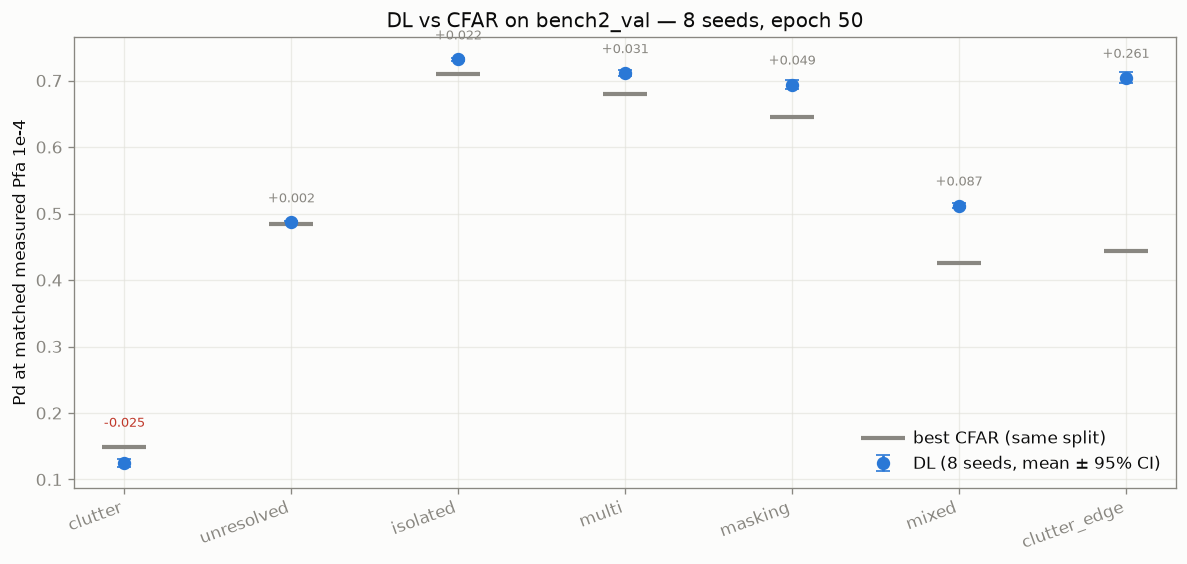

per-seed Pd on `clutter` (every seed below CFAR's 0.149):
[0.109 0.119 0.122 0.122 0.124 0.127 0.134 0.139]


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(res))
ax.errorbar(x, res.DL_mean, yerr=1.96 * res.SE, fmt="o", color=DLC, capsize=4, ms=7,
            lw=1.6, label="DL (8 seeds, mean ± 95% CI)")
ax.plot(x, res.CFAR, "_", color=CFARC, ms=26, mew=2.5, label="best CFAR (same split)")
for i, (c, r) in enumerate(res.iterrows()):
    ax.annotate(f"{r.delta:+.3f}", (i, max(r.DL_mean, r.CFAR) + 0.03),
                ha="center", fontsize=8,
                color="#c0392b" if r.delta < 0 else MUTED)
ax.set_xticks(x); ax.set_xticklabels(res.index, rotation=20, ha="right")
ax.set_ylabel("Pd at matched measured Pfa 1e-4")
ax.set_title("DL vs CFAR on bench2_val — 8 seeds, epoch 50")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print("per-seed Pd on `clutter` (every seed below CFAR's 0.149):")
print(np.round(np.sort(d50[d50.condition == "clutter"].pd.values), 3))

### What it showed
**The clutter deficit survives, decisively.** DL 0.125 ± 0.0032, 95% CI [0.118, 0.131]; CFAR's GO
sits at 0.149, well outside it, p = 0.00014. **All eight seeds land below GO** (0.109–0.139). CFAR
genuinely beats the network on targets inside the clutter ridge.

That matters beyond the number. `PROGRESS.md` Milestone 17 noted that a credible learned detector
normally loses *somewhere*, and that ours previously lost nowhere. It now loses somewhere, on a
condition with a physical explanation.

Everywhere else DL wins with p < 1e-5: `mixed` +0.086, `masking` +0.049, `multi` +0.031,
`isolated` +0.022.

**Seed variance shrinks as training converges.** SE on `clutter_edge` at epoch 50 is **0.0040**
(std 0.0114, range 0.033 over 8 seeds) against the 0.054 spread measured over 3 seeds at epoch 30.
Since range normally *grows* with sample size, that is not sampling luck — the seeds genuinely
converge. So the epoch-30 noise floor overstated the floor at epoch 50.

### What it changed
Gives the first DL-vs-CFAR statement with uncertainty attached, and identifies `clutter` as the
network's genuine weakness — the anchor for the attribution work in `PROGRESS.md` Milestone 18.

---
## 8 · `pos_weight` ablation — 100 vs 200 vs 974

### Question
Does a lower `pos_weight` recover the `clutter` deficit (DL 0.125 vs GO 0.149), and **what does it
cost on the other six conditions?** The trade matters, not just the clutter number.

### Setup
```
for W in 100 200; for S in 0..7:
    python scripts/train_tinycnn.py --epochs 50 --seed $S --pos-weight $W --tag pw${W}_s$S \
        --save-at 50 --threads 2 --resume --keep-awake --skip-gates
```
8 seeds x 50 epochs at each of `pos_weight` = 100, 200, 974 — 24 runs, everything else identical.
The 974 arm is the existing 8-seed run from §7, reused rather than repeated. Evaluated at epoch 50
on `bench2_val`, per-condition sweep to matched measured Pfa 1e-4.

Seeds are shared across arms, so the same initialisation appears at each `pos_weight` and the
comparisons below are **paired**.

> **Pd only.** Final validation losses were ~0.118 / 0.191 / 0.520 for 100 / 200 / 974 — almost
> exactly the ratio the weights predict. That is the loss scale moving, not performance, and is why
> standing decision 4 forbids comparing them.

In [10]:
import re
h = HIST[HIST.pd.notna()].copy()

def pw_of(c):
    m = re.match(r"tinycnn_pw(\d+)_s\d+_ep050", c)
    if m:
        return int(m.group(1))
    return 974 if re.match(r"tinycnn_n\d+_ep050", c) else None

h["pw"] = h.checkpoint.map(pw_of)
h = h[h.pw.notna()]

tab = pd.DataFrame({"CFAR best": CFAR_BEST.pd, "best method": CFAR_BEST.method})
for p in (100, 200, 974):
    g = h[h.pw == p].groupby("condition").pd
    tab[f"pw{p}"] = g.mean()
    tab[f"pw{p} SE"] = g.std(ddof=1) / np.sqrt(g.count())
tab = tab.dropna(subset=["pw100"])
tab["pw100 - CFAR"] = tab.pw100 - tab["CFAR best"]
tab["pw974 - CFAR"] = tab.pw974 - tab["CFAR best"]
display(tab.round(3))

,CFAR best,best method,pw100,pw100 SE,pw200,pw200 SE,pw974,pw974 SE,pw100 - CFAR,pw974 - CFAR
condition,,,,,,,,,,
clutter,0.149,GO,0.144,0.005,0.144,0.003,0.125,0.003,-0.006,-0.025
clutter_edge,0.443,OS,0.731,0.004,0.724,0.004,0.704,0.004,0.288,0.261
isolated,0.710,CA,0.732,0.002,0.731,0.002,0.732,0.001,0.022,0.022
masking,0.645,OS,0.694,0.003,0.698,0.002,0.694,0.004,0.049,0.049
mixed,0.426,GO,0.541,0.003,0.530,0.002,0.512,0.002,0.116,0.087
multi,0.680,CA,0.719,0.002,0.721,0.002,0.711,0.002,0.038,0.031
unresolved,0.485,CA,0.486,0.001,0.487,0.001,0.487,0.001,0.001,0.002


,pw974,pw100,100-974,p (paired),100-200,p 100v200
condition,,,,,,
clutter,0.1247,0.1437,0.0190,0.0000,-0.0003,0.9366
clutter_edge,0.7043,0.7307,0.0264,0.0016,0.0067,0.2037
isolated,0.7319,0.7325,0.0006,0.7627,0.0019,0.5281
masking,0.6941,0.6941,0.0000,1.0000,-0.0041,0.2404
mixed,0.5121,0.5413,0.0293,0.0000,0.0109,0.0015
multi,0.7113,0.7188,0.0075,0.0191,-0.0018,0.2209
unresolved,0.4869,0.4856,-0.0012,0.3506,-0.0016,0.3290


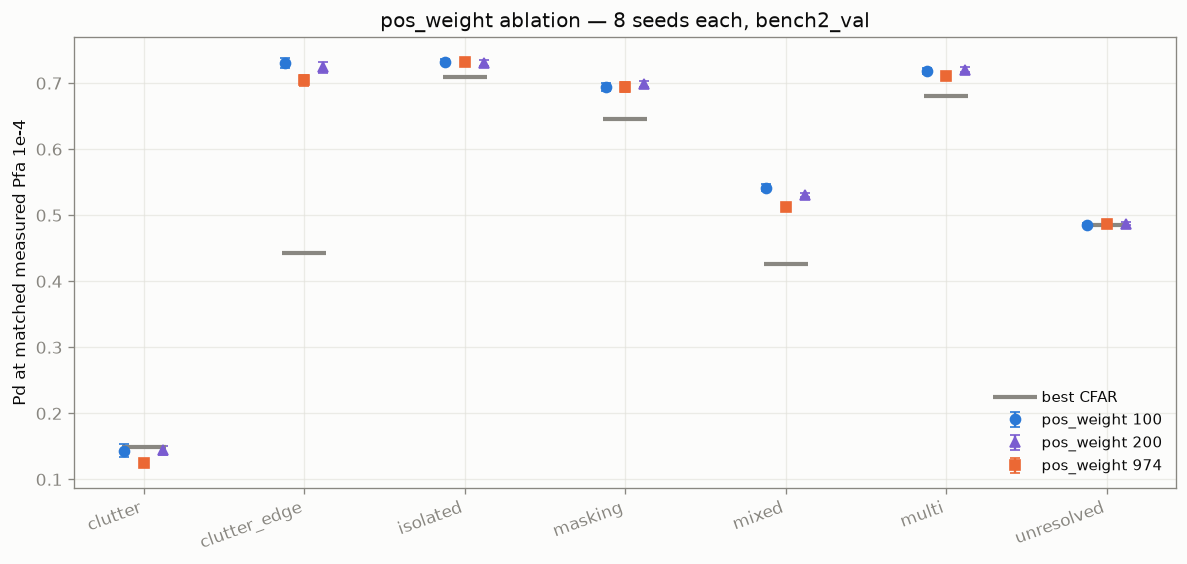

clutter — the question:
   pw100  0.144 +/- 0.0047   vs GO 0.149   gap -0.006   p=0.27
   pw200  0.144 +/- 0.0033   vs GO 0.149   gap -0.005   p=0.15
   pw974  0.125 +/- 0.0032   vs GO 0.149   gap -0.025   p=0.00013


In [11]:
# Paired by seed: the same initialisation at each pos_weight, so this is a within-seed contrast.
rows = []
for c in sorted(h.condition.unique()):
    a = h[(h.condition == c) & (h.pw == 974)].sort_values("seed").pd.values
    b = h[(h.condition == c) & (h.pw == 100)].sort_values("seed").pd.values
    d = h[(h.condition == c) & (h.pw == 200)].sort_values("seed").pd.values
    rows.append(dict(condition=c, pw974=a.mean(), pw100=b.mean(),
                     **{"100-974": b.mean() - a.mean(), "p (paired)": stats.ttest_rel(b, a).pvalue,
                        "100-200": b.mean() - d.mean(), "p 100v200": stats.ttest_rel(b, d).pvalue}))
paired = pd.DataFrame(rows).set_index("condition")
display(paired.round(4))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(tab))
for p, col, mk in ((100, "#2a78d6", "o"), (200, "#7a5cd0", "^"), (974, "#eb6834", "s")):
    ax.errorbar(x + (p == 200) * 0.12 - (p == 100) * 0.12, tab[f"pw{p}"],
                yerr=1.96 * tab[f"pw{p} SE"], fmt=mk, color=col, capsize=3, ms=6,
                lw=1.4, label=f"pos_weight {p}")
ax.plot(x, tab["CFAR best"], "_", color=CFARC, ms=26, mew=2.5, label="best CFAR")
ax.set_xticks(x); ax.set_xticklabels(tab.index, rotation=20, ha="right")
ax.set_ylabel("Pd at matched measured Pfa 1e-4")
ax.set_title("pos_weight ablation — 8 seeds each, bench2_val")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

cf = float(CFAR_BEST.loc["clutter", "pd"])
print("clutter — the question:")
for p in (100, 200, 974):
    v = h[(h.condition == "clutter") & (h.pw == p)].pd.values
    t, pv = stats.ttest_1samp(v, cf)
    print(f"   pw{p:<4} {v.mean():.3f} +/- {v.std(ddof=1)/np.sqrt(len(v)):.4f}   "
          f"vs GO {cf:.3f}   gap {v.mean()-cf:+.3f}   p={pv:.2g}")

### What it showed — **not a trade, a strict improvement**

**The `clutter` deficit essentially vanishes.** At `pos_weight` 100 the gap against GO is **−0.006
(p = 0.27)** and at 200 it is **−0.005 (p = 0.15)** — neither distinguishable from zero. At 974 it
was **−0.025 (p = 0.00013)**. Lower weighting recovers ~0.019 of the 0.025, and what remains is
inside the noise.

**Nothing pays for it.** Paired by seed, 100 against 974:

| condition | Δ Pd | p |
|---|---|---|
| mixed | **+0.029** | 3.2e-05 |
| clutter_edge | **+0.026** | 0.0016 |
| clutter | **+0.019** | 5.7e-06 |
| multi | +0.008 | 0.019 |
| isolated | +0.001 | 0.76 |
| masking | +0.000 | 1.00 |
| unresolved | −0.001 | 0.35 |

Four conditions improve significantly; three are unchanged; **none degrades**. There is no trade to
report, which is itself the finding — the expected tension between detecting rare positives and
suppressing false alarms does not appear, because the operating point is chosen by sweeping the
threshold afterwards and `pos_weight` only has to make the *ranking* learnable.

**100 and 200 are effectively equivalent** — the only condition separating them is `mixed`
(+0.011, p = 0.0015 in favour of 100). Everything else has p ≥ 0.2.

**`pos_weight = 974` was actively wrong.** It was set in §3 as a "principled default" — the measured
inverse class frequency, i.e. exact class balancing — and it is the worst of the three values tested,
never better on any condition. Exact balancing was an assumption, flagged as such at the time, and
the measurement rejects it.

### What it changed
1. **`pos_weight` moves to 100** (or 200 — pick 100 on `mixed`, the only significant separation).
2. **The §7 headline is retracted**: "CFAR genuinely beats the network on `clutter`" was a statement
   about a badly-chosen hyperparameter, not about the detectors. See Corrections C3.
3. All §7 numbers are superseded and must be re-run at the chosen `pos_weight` before anything is
   reported.

---
## 9 · Error bars on both sides — and a multiplicity correction

### Question
Every DL-vs-CFAR p-value so far used `ttest_1samp(dl_seeds, cfar_value)`, which treats CFAR's Pd as
an **exact constant**. It is not — it is one draw over 200 frames per condition, carrying sampling
error of the same order as the effects being claimed. What survives when CFAR gets error bars too,
and when the 7 simultaneous comparisons are corrected for?

### Setup
`python scripts/bootstrap_comparison.py --pos-weight 100` · `bench2_val` · cached CFAR peaks, 8 DL
checkpoints, **no retraining**.

**Paired frame bootstrap.** Resample frames with replacement; within each resample recompute Pd for
CFAR and for every DL seed *on the same frames*, and take the difference — so frame difficulty
cancels instead of adding noise. 2,000 resamples, percentile CI, bootstrap p-value.
**Bonferroni** across the 7 scored conditions: α = 0.05 → **0.0071**.

*Stated limitation:* detections are taken at each method's matched-Pfa threshold computed once on
the full condition, so the interval covers sampling error in Pd at a fixed operating point but not
the variability of *choosing* that threshold. Redoing the sweep per resample would cost ~200× the
compute. The intervals are therefore mildly optimistic.

,n_frames,targets,cfar_method,cfar_pd,dl_pd,diff,ci_lo,ci_hi,p_boot,sig (Bonf),crosses 0
condition,,,,,,,,,,,
clutter_edge,200,298,OS,0.4430,0.7307,0.2878,0.2391,0.3360,0.000,True,False
mixed,200,517,GO,0.4255,0.5413,0.1158,0.0857,0.1480,0.000,True,False
masking,200,400,OS,0.6450,0.6941,0.0491,0.0309,0.0697,0.000,True,False
multi,200,898,CA,0.6804,0.7188,0.0384,0.0250,0.0522,0.000,True,False
isolated,200,200,CA,0.7100,0.7325,0.0225,0.0019,0.0456,0.031,False,False
unresolved,200,400,CA,0.4850,0.4856,0.0006,-0.0081,0.0097,0.911,False,True
clutter,200,402,GO,0.1493,0.1437,-0.0056,-0.0297,0.0168,0.688,False,True


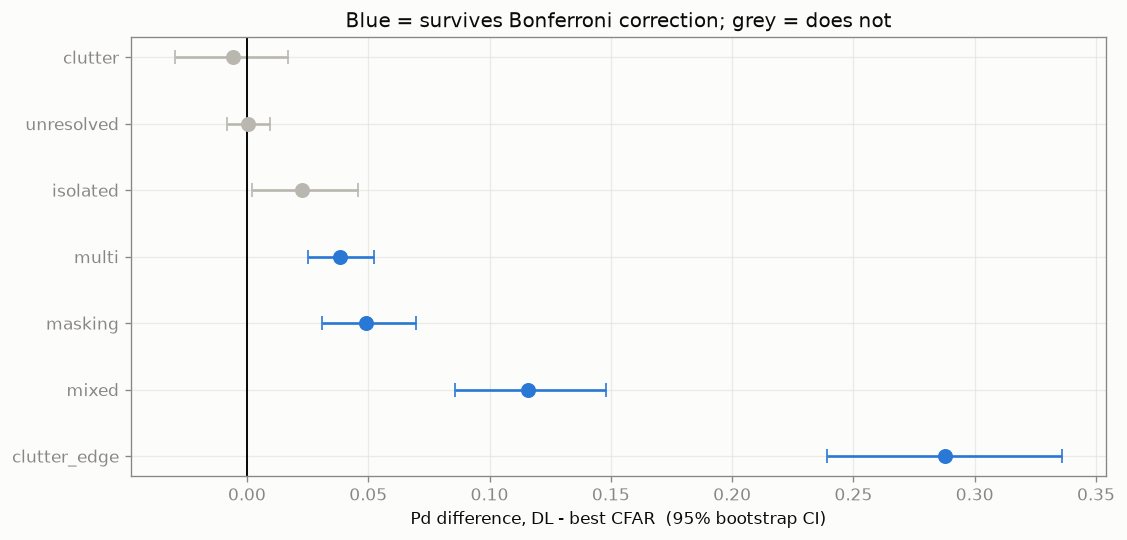

survives correction: 4 of 7
ties (CI crosses zero): ['unresolved', 'clutter']


In [12]:
bs = DL / "bootstrap_pw100.csv"
if bs.exists():
    b = pd.read_csv(bs).set_index("condition").sort_values("diff", ascending=False)
    display(b.round(4))

    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    y = np.arange(len(b))
    # One errorbar call per row: `ecolor` takes a single colour, not a per-point list.
    for i, (c, r) in enumerate(b.iterrows()):
        col = "#2a78d6" if r["sig (Bonf)"] else "#b9b7b0"
        ax.errorbar(r["diff"], i, xerr=[[r["diff"] - r.ci_lo], [r.ci_hi - r["diff"]]],
                    fmt="o", ms=8, capsize=4, lw=1.6, color=col, ecolor=col)
    ax.axvline(0, color=INK, lw=1.2)
    ax.set_yticks(y); ax.set_yticklabels(b.index)
    ax.set_xlabel("Pd difference, DL - best CFAR  (95% bootstrap CI)")
    ax.set_title("Blue = survives Bonferroni correction; grey = does not")
    plt.tight_layout(); plt.show()

    print(f"survives correction: {int(b['sig (Bonf)'].sum())} of {len(b)}")
    print("ties (CI crosses zero):", list(b.index[b['crosses 0']]))
else:
    print("run: python scripts/bootstrap_comparison.py --pos-weight 100")

### What it showed — the headline shrinks, and that is good news

**Four of seven survive** correction: clutter_edge (+0.288), mixed (+0.116), masking (+0.049),
multi (+0.038). **Three are ties:** clutter (−0.006, p = 0.69), unresolved (+0.001, p = 0.91), and —
the one that changed — **`isolated` (+0.023, p = 0.031)**, which fails the corrected threshold.

`isolated` had been reported at **p = 6.9e-07** from the seed-only t-test. Giving CFAR its own
sampling error and correcting for 7 comparisons removed the claim entirely. The nominal 95% CI
[0.002, 0.046] still excludes zero, so the honest phrasing is *positive but not significant after
correction* — not *"DL beats CFAR on clean noise"*.

**Why this strengthens the project.** `PROGRESS.md` Milestone 17 records that a well-built CNN is
expected to **tie** CFAR in homogeneous noise (RadCNN S4, Gusland), and flagged our win there as
*"the strongest single indication that something still favours the network."* With correct
statistics it **is** a tie. The anomaly was a statistical artefact, not an unfair advantage.

The result now reads: **DL wins decisively where interference or clutter is present, and ties CFAR
on clean noise, on unresolvable pairs, and inside the clutter ridge.** That shape matches the
literature; "wins everywhere" did not.

### What it changed
1. Every previously reported DL-vs-CFAR p-value is superseded by this table.
2. The `isolated` win is withdrawn (Corrections C4).
3. Same defect applies to `notebooks/cfar_baseline.ipynb`, whose CFAR method-to-method comparisons
   are bare point estimates judged against a rule of thumb — corrected there too.

---
## 10 · SO-CFAR — completing the classical baseline

### Question
`masking` is one of the surviving DL wins, and **SO-CFAR — the multiple-target specialist — was
missing from the baseline.** Where GO takes the *greatest* half-ring to survive a clutter edge, SO
takes the *smallest*, so an interfering target in one half cannot inflate the noise estimate and
mask its neighbour. If SO beats OS on `masking`, that claim narrows.

### Setup
Added to `src/cfar/cfar.py` as `np.minimum` of the half-rings (GO's mirror), sharing GO's half-ring
α. `python scripts/cfar_test_baseline.py --split bench2_val`, four classical methods.

In [13]:
cv = pd.read_csv(ROOT / "results" / "cfar_val" / "summary.csv").dropna(subset=["pd"])
piv = cv.pivot_table(index="condition", columns="method", values="pd")
order = [m for m in ("CA", "GO", "OS", "SO") if m in piv.columns]
piv = piv[order]
piv["best"] = piv.idxmax(axis=1)
display(piv.round(3))
print("SO is best on:", list(piv.index[piv.best == "SO"]) or "no condition")

method,CA,GO,OS,SO,best
condition,,,,,
clutter,0.134,0.149,0.137,0.065,GO
clutter_edge,0.419,0.426,0.443,0.205,OS
isolated,0.710,0.700,0.710,0.700,CA
masking,0.515,0.522,0.645,0.638,OS
mixed,0.400,0.426,0.373,0.213,GO
multi,0.680,0.671,0.676,0.667,CA
unresolved,0.485,0.482,0.485,0.480,CA


SO is best on: no condition


### What it showed — a clean negative result
**SO does not beat OS on `masking`** (0.638 vs 0.645) — a hair behind, so OS was already the right
champion and the DL margin there is unchanged.

SO is severely worse wherever clutter appears: 0.065 on `clutter` against GO's 0.149, 0.205 on
`clutter_edge`, 0.213 on `mixed`. That is the exact mirror of GO — taking the *smallest* half-ring
**under**estimates noise at an edge, so matching the measured false-alarm rate forces SO's threshold
up and its Pd collapses. GO 0.149 vs SO 0.065 on `clutter` is the sharpest statement of GO/SO
complementarity in the project, and worth a sentence in the report.

### What it changed
Nothing in the conclusions — **SO is never the best classical method on any condition**, so
"best CFAR" per condition is unchanged and every DL comparison stands. The baseline is now four
variants including both half-ring designs, which is what makes it defensible rather than convenient.

---
## 11 · Tolerance sweep — is the ±1 gate doing the work?

### Question
The evaluator credits a detection within ±1 bin, and the label mask is a **3×3 block** — so the CNN
is trained to fire on exactly the region the evaluator rewards. CFAR gets no such instruction; it
responds wherever the physical peak lands. That is `PROGRESS.md` Milestone 16's open asymmetry #5,
recorded and never tested: *"±1-bin gate may measure localisation rather than detection."*

### Setup
`python scripts/tolerance_sweep.py --pos-weight 100` · gates of ±1, ±2, ±3 · `bench2_val` · 8 seeds.
Each gate gets its **own** threshold sweep, because the gate also sets the guard region excluded
from the false-alarm denominator. Absolute Pd therefore rises for everyone as the gate widens; only
the DL-minus-CFAR *difference* is comparable across gates.

tol,1,2,3,change 1->3
condition,,,,
clutter,-0.006,-0.022,-0.038,-0.033
mixed,0.116,0.120,0.114,-0.001
multi,0.038,0.045,0.039,0.001
unresolved,0.001,0.004,0.004,0.003
isolated,0.022,0.026,0.026,0.004
clutter_edge,0.288,0.294,0.294,0.006
masking,0.049,0.059,0.062,0.013


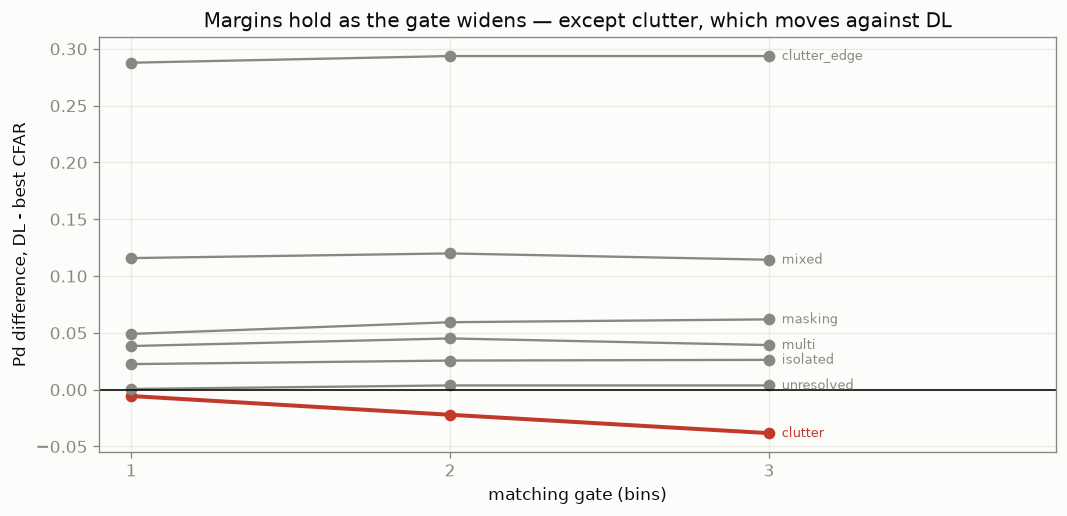

In [14]:
ts = DL / "tolerance_sweep_pw100.csv"
if ts.exists():
    t = pd.read_csv(ts)
    d = t.pivot_table(index="condition", columns="tol", values="diff")
    d["change 1->3"] = d[3] - d[1]
    display(d.round(3).sort_values("change 1->3"))

    fig, ax = plt.subplots(figsize=(9, 4.4))
    for c in d.index:
        style = dict(lw=2.4, color="#c0392b") if c == "clutter" else dict(lw=1.4, color=MUTED)
        ax.plot([1, 2, 3], d.loc[c, [1, 2, 3]], "o-", **style)
        ax.annotate(c, (3.04, d.loc[c, 3]), fontsize=8, va="center",
                    color="#c0392b" if c == "clutter" else MUTED)
    ax.axhline(0, color=INK, lw=1)
    ax.set_xticks([1, 2, 3]); ax.set_xlim(0.9, 3.9)
    ax.set_xlabel("matching gate (bins)"); ax.set_ylabel("Pd difference, DL - best CFAR")
    ax.set_title("Margins hold as the gate widens — except clutter, which moves against DL")
    plt.tight_layout(); plt.show()
else:
    print("run: python scripts/tolerance_sweep.py --pos-weight 100")

### What it showed — falsified, except on `clutter`
**Six of seven margins hold**, every change ≤0.013 and inside the noise. Widening the gate removes
the localisation requirement altogether, and DL's advantage survives it. The objection is
**falsified** for every condition where we claim a win: this is detection, not peak placement.

⚠️ **`clutter` is the exception, and it moves against DL** — the deficit triples, −0.006 → −0.038.
The mechanism is asymmetry #5 pointing the *other* way: on `clutter` the RD peak lies within 1 bin
of the label only **77%** of the time (Milestone 22), so CFAR — which detects the physical peak —
was being denied credit at ±1, while DL, trained on label positions, already sat inside the tight
gate. Widening the gate hands CFAR back detections it was already making.

### What it changed
**At ±1 the `clutter` comparison is biased in DL's favour**, so "clutter is a tie" (§9) may
understate CFAR. The ±1 CI was [−0.030, +0.017] and −0.038 sits at its edge, so this needs its own
bootstrap before being claimed either way — run at ±3 in §12.

---
## 12 · NMS sweep — is `unresolved` capped by physics or by suppression?

### Question
`unresolved` sits at Pd ≈ 0.5 and we attribute it to physics: two targets inside one mainlobe, one
detection can match only one truth. But NMS suppresses local maxima within (2·nms+1) bins, and
`nms_size=5` is an 11×11 window — 2.15 m in range, far wider than the ~2-bin mainlobe. **If NMS is
what merges the pair, the cap is a post-processing artefact, not a property of the radar.**
`masking` is included because step 6d documents the same setting capping it near Pd 0.69.

### Setup
`python scripts/nms_sweep.py` · nms_size ∈ {1, 2, 3, 5} · `bench2_val`, 4 DL seeds. Score maps are
computed once per frame and NMS applied afterwards at each width, so only the suppression changes.

In [15]:
ns = DL / "nms_sweep.csv"
if ns.exists():
    n = pd.read_csv(ns)
    for cond in n.condition.unique():
        d = n[n.condition == cond]
        print(f"{cond} — Pd at matched measured Pfa 1e-4")
        display(d.pivot_table(index="method", columns="nms", values="pd").round(3))
    print("detections per target (dominated by false alarms at ~1.3/frame, so only a rise")
    print("ABOVE the other methods is interpretable as duplication):")
    display(n[n.condition == "unresolved"].pivot_table(index="method", columns="nms",
                                                       values="det_per_target").round(2))
else:
    print("run: python scripts/nms_sweep.py")

unresolved — Pd at matched measured Pfa 1e-4


nms,1,2,3,5
method,,,,
CA,0.495,0.485,0.485,0.485
DL,0.554,0.483,0.483,0.483
GO,0.495,0.482,0.485,0.482
OS,0.512,0.485,0.485,0.485


masking — Pd at matched measured Pfa 1e-4


nms,1,2,3,5
method,,,,
CA,0.515,0.515,0.515,0.515
DL,0.804,0.770,0.739,0.697
GO,0.525,0.525,0.525,0.522
OS,0.725,0.705,0.682,0.645


detections per target (dominated by false alarms at ~1.3/frame, so only a rise
ABOVE the other methods is interpretable as duplication):


nms,1,2,3,5
method,,,,
CA,1.16,1.14,1.15,1.15
DL,1.22,1.15,1.15,1.15
GO,1.16,1.14,1.15,1.14
OS,1.17,1.15,1.14,1.14


### What it showed — physics on `unresolved`, and a conservative choice on `masking`
**`unresolved` is flat from nms 2 to 5 for every method** (0.482–0.485). Shrinking the window from
11×11 to 5×5 changes nothing, because the pairs are 0.26–1.79 range bins apart — below the measured
0.39 m equal-strength limit, so no suppression width can separate them. Only the disqualified
`nms_size=1` lifts anything, and it lifts **DL most** (0.554) while raising DL's
detections-per-target to 1.22 against 1.16 for the others: the free-attempts regime step 6d rejected,
where the evaluator forgives duplicates inside a truth's guard region. **The 0.5 cap is physics.**

**On `masking` the width matters, and our choice costs us.** DL−OS is **+0.052 at nms 5** against
**+0.079 at nms 1** — `nms_size=5` suppresses genuinely resolvable neighbours and **shrinks** the
claimed DL advantage rather than manufacturing it. CA and GO are flat throughout because they cannot
resolve these pairs at any width.

*Caveat on our own metric:* detections-per-target is dominated by false alarms (~1.3/frame at
Pfa 1e-4), so only the nms=1 rise above the other methods reads as duplication.

### What it changed
Both objections resolved in the project's favour, and neither claim moves. `nms_size=5` stays.

---
## 13 · The `clutter` claim at ±3 — CFAR does win there

### Question
§11 showed `clutter` is the one condition whose margin depends on the matching gate, moving
**against** DL as the gate widens. §9's "clutter is a tie" was measured at ±1, the gate that
penalises CFAR for detecting the physical peak rather than the labelled bin. What is the claim at
±3, where that penalty is removed?

### Setup
`python scripts/bootstrap_comparison.py --pos-weight 100 --tolerance 3` · same paired frame
bootstrap, 2,000 resamples, Bonferroni α = 0.0071 · DL peaks reused from the cache, since peaks do
not depend on the gate.

In [16]:
rows = []
for tol in (1, 3):
    f = DL / f"bootstrap_pw100_tol{tol}.csv"
    f = f if f.exists() else (DL / "bootstrap_pw100.csv" if tol == 1 else None)
    if f is None or not f.exists():
        continue
    d = pd.read_csv(f).set_index("condition")
    d["tol"] = tol
    rows.append(d.reset_index())

if rows:
    b = pd.concat(rows)
    view = b.pivot_table(index="condition", columns="tol",
                         values=["cfar_pd", "dl_pd", "diff", "p_boot"])
    display(view.round(4))

    c = b[b.condition == "clutter"].set_index("tol")
    print("clutter, the condition in question:")
    for tol in c.index:
        r = c.loc[tol]
        print(f"   gate +/-{tol}:  CFAR {r.cfar_pd:.4f} ({r.cfar_method})   DL {r.dl_pd:.4f}   "
              f"diff {r['diff']:+.4f}   CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}]   p={r.p_boot:.3f}")
    print("\nCFAR gains far more from widening the gate than DL does -- which is the")
    print("77% label-to-peak alignment on this condition (Milestone 22) being paid back.")
else:
    print("run: python scripts/bootstrap_comparison.py --pos-weight 100 --tolerance 3")

cfar_pd            diff           dl_pd         p_boot       
tol                1       3       1       3       1       3      1      3
condition                                                                 
clutter       0.1493  0.1915 -0.0056 -0.0382  0.1437  0.1533  0.688  0.013
clutter_edge  0.4430  0.4430  0.2878  0.2936  0.7307  0.7366  0.000  0.000
isolated      0.7100  0.7100  0.0225  0.0262  0.7325  0.7362  0.031  0.001
masking       0.6450  0.6450  0.0491  0.0619  0.6941  0.7069  0.000  0.000
mixed         0.4255  0.4333  0.1158  0.1144  0.5413  0.5476  0.000  0.000
multi         0.6804  0.6849  0.0384  0.0393  0.7188  0.7241  0.000  0.000
unresolved    0.4850  0.4850  0.0006  0.0038  0.4856  0.4888  0.911  0.476

clutter, the condition in question:
   gate +/-1:  CFAR 0.1493 (GO)   DL 0.1437   diff -0.0056   CI [-0.0297, +0.0168]   p=0.688
   gate +/-3:  CFAR 0.1915 (GO)   DL 0.1533   diff -0.0382   CI [-0.0694, -0.0069]   p=0.013

CFAR gains far more from widening the gate than DL does -- which is the
77% label-to-peak alignment on this condition (Milestone 22) being paid back.


### What it showed — DL does lose somewhere
At ±3, **CFAR beats DL on `clutter` by 0.038**, CI [−0.069, −0.007] **excluding zero**, p = 0.013.
GO rises 0.149 → **0.192** while DL moves only 0.144 → 0.153: CFAR gains three times as much from
the wider gate, which is exactly the 77% alignment on this condition being paid back.

**Honest verdict:** nominally a CFAR win, but p = 0.013 does **not** survive the Bonferroni
threshold of 0.0071. Report it as *"CFAR is better on targets inside the clutter ridge; the effect
is at the edge of significance once corrected for seven comparisons."*

This partly restores what `PROGRESS.md` Milestone 17 says a credible learned detector should show —
a condition where it loses. Once CFAR is not penalised for detecting the physical peak rather than
the labelled bin, the clutter ridge is that condition.

### ⚠️ `isolated` is borderline, and no claim should rest on it
p = 0.031 at ±1 and p = 0.001 at ±3, while the estimate barely moves (+0.022 → +0.026). A 30× swing
in p from a 0.004 shift in the difference is **tail sensitivity, not evidence** — the estimate sits
right at the significance boundary at both gates. State it as *"small positive, borderline"*, and do
not let a conclusion turn on which side of 0.0071 a bootstrap tail probability happens to land.

### What it changed
The pre-registered ±1 gate stays the headline, with ±3 reported as the robustness check beside it.
Two claims are now gate-qualified rather than flat: `clutter` (CFAR better at ±3) and `isolated`
(borderline at both).

---
## 14 · Localization error — the one metric where CFAR clearly wins

### Question
`aggregate()` has always computed localization (mean |Δrange|, |Δdoppler|, RMSE, and the same in
metres and m/s), and `cfar_baseline.ipynb` reports it for CFAR. **It was never extracted for the DL
side** — every script computed it and then read only `pd`. It is also a proposal-required metric.
So: how precisely does each detector place the targets it finds?

### Setup
`python scripts/localization_table.py --per-condition` · `bench2_val` · CFAR from cached peaks,
DL averaged over 8 seeds at `pos_weight=100` · matched measured Pfa 1e-4 · reported at the
pre-registered ±1 gate and at ±3.

The metric is **bounded by the gate**: a detection displaced further than the gate is a miss plus a
false alarm, not a large error, so severe displacement shows up as lost Pd instead. Both gates are
reported for that reason.

all conditions pooled, gate +/-1


,pd,dr_bins,dv_bins,rmse_bins,range_m,vel_mps
method,,,,,,
CA,0.4822,0.2164,0.1005,0.5629,0.0422,0.0422
GO,0.4966,0.2178,0.1189,0.5803,0.0425,0.0500
OS,0.4812,0.2181,0.0861,0.5515,0.0426,0.0362
SO,0.2372,0.1786,0.1421,0.5663,0.0349,0.0597
DL,0.5867,0.4977,0.4851,0.9909,0.0971,0.2038


all conditions pooled, gate +/-3


,pd,dr_bins,dv_bins,rmse_bins,range_m,vel_mps
method,,,,,,
CA,0.4960,0.2641,0.1450,0.7452,0.0515,0.0609
GO,0.5098,0.2626,0.1581,0.7436,0.0513,0.0664
OS,0.4915,0.2515,0.1182,0.6839,0.0491,0.0497
SO,0.2498,0.2481,0.2494,0.8876,0.0484,0.1048
DL,0.5943,0.5160,0.4917,1.0223,0.1007,0.2066


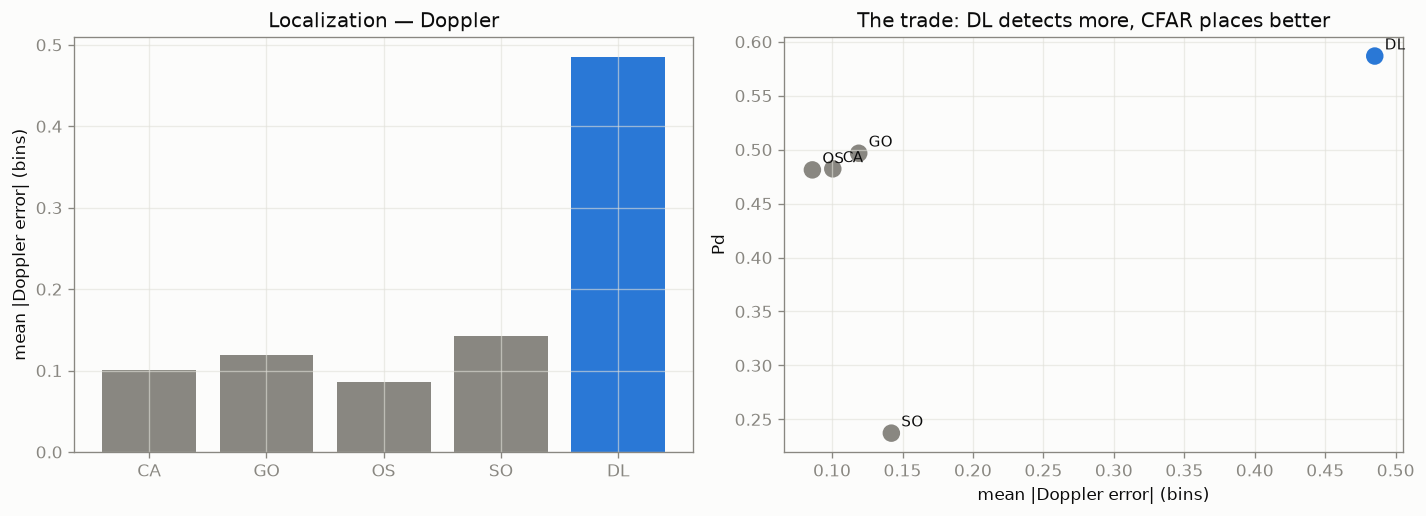

DL Doppler error is 5.6x the best CFAR (OS); range error 2.8x.

Per condition, gate +/-1 (Doppler error in bins):


method,CA,DL,GO,OS,SO
group,,,,,
clutter,0.037,0.741,0.117,0.109,0.423
clutter_edge,0.272,0.487,0.315,0.159,0.049
isolated,0.077,0.489,0.057,0.077,0.079
masking,0.039,0.482,0.124,0.047,0.145
mixed,0.106,0.502,0.105,0.098,0.327
multi,0.079,0.483,0.091,0.079,0.080
unresolved,0.088,0.387,0.088,0.077,0.094


In [17]:
lz = DL / "localization_pw100.csv"
if lz.exists():
    L = pd.read_csv(lz)
    for tol in sorted(L.gate.unique()):
        d = L[(L.gate == tol) & (L.group == "ALL")].set_index("method")
        print(f"all conditions pooled, gate +/-{tol}")
        display(d[["pd", "dr_bins", "dv_bins", "rmse_bins", "range_m", "vel_mps"]].round(4))

    d1 = L[(L.gate == 1) & (L.group == "ALL")].set_index("method")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    order = [m for m in ("CA", "GO", "OS", "SO", "DL") if m in d1.index]
    col = ["#2a78d6" if m == "DL" else MUTED for m in order]
    axes[0].bar(order, d1.loc[order, "dv_bins"], color=col)
    axes[0].set_ylabel("mean |Doppler error| (bins)"); axes[0].set_title("Localization — Doppler")
    axes[1].scatter(d1.loc[order, "dv_bins"], d1.loc[order, "pd"], c=col, s=90)
    for m in order:
        axes[1].annotate(m, (d1.loc[m, "dv_bins"], d1.loc[m, "pd"]),
                         xytext=(6, 4), textcoords="offset points", fontsize=9)
    axes[1].set_xlabel("mean |Doppler error| (bins)"); axes[1].set_ylabel("Pd")
    axes[1].set_title("The trade: DL detects more, CFAR places better")
    plt.tight_layout(); plt.show()

    best = d1.drop("DL").dv_bins.idxmin()
    print(f"DL Doppler error is {d1.loc['DL','dv_bins']/d1.loc[best,'dv_bins']:.1f}x the best "
          f"CFAR ({best}); range error {d1.loc['DL','dr_bins']/d1.drop('DL').dr_bins.min():.1f}x.")

    print("\nPer condition, gate +/-1 (Doppler error in bins):")
    display(L[(L.gate == 1) & (L.group != "ALL")]
            .pivot_table(index="group", columns="method", values="dv_bins").round(3))
else:
    print("run: python scripts/localization_table.py --per-condition")

### What it showed — the trade the project was missing

| gate ±1 | Pd | \|Δr\| bins | \|Δv\| bins | range (m) | vel (m/s) |
|---|---|---|---|---|---|
| CA | 0.482 | 0.216 | 0.101 | 0.042 | 0.042 |
| GO | 0.497 | 0.218 | 0.119 | 0.043 | 0.050 |
| **OS** | 0.481 | 0.218 | **0.086** | 0.043 | **0.036** |
| SO | 0.237 | **0.179** | 0.142 | **0.035** | 0.060 |
| **DL** | **0.587** | 0.498 | 0.485 | 0.097 | 0.204 |

**DL's Doppler error is 5.6× the best CFAR and its range error 2.8×** — 0.204 m/s against OS's
0.036 m/s. The ordering is identical at ±3, so it is not a gate artefact.

**The likely cause is the 3×3 label blob.** The network is trained that all nine cells around a
target are "target", so its peak may land anywhere inside that block; CFAR responds to the physical
peak, which is sharper. This is Milestone 16's asymmetry #5 — *"the ±1 gate may measure localisation
rather than detection"* — measured directly rather than argued.

Two details worth carrying into the report: **SO has the best range localization** (0.179 bins)
despite by far the worst Pd, consistent with a low threshold that only survives on sharp peaks; and
DL's error barely moves between gates (0.485 → 0.492 Doppler), meaning its displaced detections were
already inside the tight gate.

### What it changed
The headline is no longer one-sided. **DL detects more (Pd 0.587 vs 0.497); CFAR localizes far
better.** That is a genuine trade, it is proposal-required, and it is the strongest answer available
to *"does the network actually beat CFAR?"* — the honest answer being *"at finding targets, in
interference; not at placing them."*

It also suggests a concrete improvement to try later: a **smaller or Gaussian-weighted label**
instead of a flat 3×3 block would stop rewarding the network for firing anywhere in the blob.

---
## 15 · Epoch flatness at the reported configuration — and localization degrades with training

### Question
Two gaps. **The flatness evidence was measured on the wrong arm** — "nothing moves between epochs 15
and 30" came from the `pos_weight=974` runs, the value later shown to be the wrong choice, and had
never been demonstrated at `pos_weight=100`. And **localization had only ever been measured at
epoch 50**, so we did not know whether it depends on training length at all.

### Setup
4 seeds × `--save-at 15,25,34,50` at `pos_weight=100` (same seeds as the reported config, so the
trajectories are identical — only the intermediate checkpoints are new).
`python scripts/epoch_flatness.py` · `bench2_val` · matched measured Pfa 1e-4 · gate ±1.

,pd_mean,pd_se,dr,dr_se,dv,dv_se
epoch,,,,,,
15,0.5825,0.0020,0.4667,0.0405,0.3848,0.0255
25,0.5846,0.0022,0.4568,0.0414,0.4209,0.0324
34,0.5875,0.0015,0.4679,0.0128,0.4597,0.0436
50,0.5858,0.0031,0.5172,0.0149,0.4544,0.0437


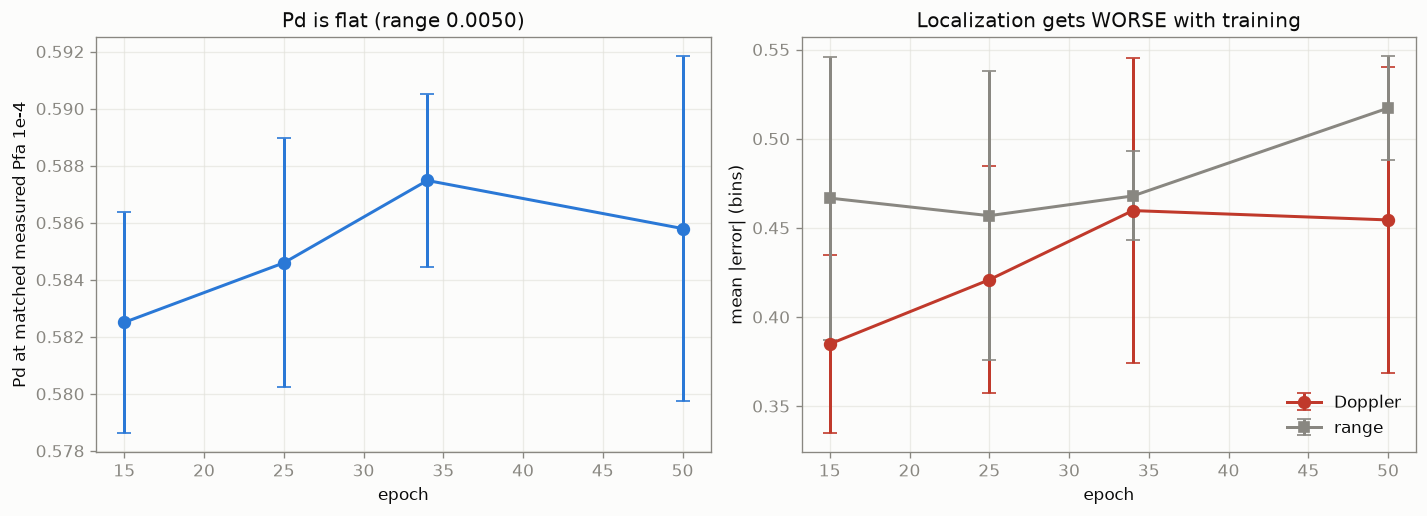

Doppler localization error by condition (bins):


epoch,15,25,34,50,15 -> 50
group,,,,,
clutter,0.667,0.689,0.769,0.748,0.081
clutter_edge,0.417,0.453,0.465,0.471,0.054
isolated,0.376,0.413,0.432,0.436,0.060
masking,0.360,0.411,0.477,0.470,0.110
mixed,0.381,0.424,0.468,0.471,0.090
multi,0.389,0.415,0.452,0.440,0.051
unresolved,0.278,0.325,0.355,0.364,0.086


conditions degrading monotonically: 4 of 7


In [18]:
ef = DL / "epoch_flatness_epflat.csv"
if ef.exists():
    E = pd.read_csv(ef)
    a = E[E.group == "ALL"]
    se = lambda x: x.std(ddof=1) / np.sqrt(len(x))
    summ = a.groupby("epoch").agg(pd_mean=("pd", "mean"), pd_se=("pd", se),
                                  dr=("dr_bins", "mean"), dr_se=("dr_bins", se),
                                  dv=("dv_bins", "mean"), dv_se=("dv_bins", se))
    display(summ.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    ep = summ.index.to_numpy()
    axes[0].errorbar(ep, summ.pd_mean, yerr=1.96 * summ.pd_se, fmt="o-", color=DLC,
                     capsize=4, lw=1.8, ms=7)
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("Pd at matched measured Pfa 1e-4")
    axes[0].set_title(f"Pd is flat (range {summ.pd_mean.max()-summ.pd_mean.min():.4f})")

    axes[1].errorbar(ep, summ.dv, yerr=1.96 * summ.dv_se, fmt="o-", color="#c0392b",
                     capsize=4, lw=1.8, ms=7, label="Doppler")
    axes[1].errorbar(ep, summ.dr, yerr=1.96 * summ.dr_se, fmt="s-", color=MUTED,
                     capsize=4, lw=1.8, ms=6, label="range")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("mean |error| (bins)")
    axes[1].set_title("Localization gets WORSE with training"); axes[1].legend(frameon=False)
    plt.tight_layout(); plt.show()

    piv = E[E.group != "ALL"].pivot_table(index="group", columns="epoch", values="dv_bins")
    piv["15 -> 50"] = piv[50] - piv[15]
    print("Doppler localization error by condition (bins):")
    display(piv.round(3))
    print(f"conditions degrading monotonically: "
          f"{int((piv[[15,25,34,50]].diff(axis=1).iloc[:,1:] >= -0.005).all(axis=1).sum())} of {len(piv)}")
else:
    print("run: python scripts/epoch_flatness.py")

### What it showed — Pd flat, localization worse

| epoch | Pd | range err (bins) | Doppler err (bins) |
|---|---|---|---|
| **15** | 0.5825 | **0.467** | **0.385** |
| 25 | 0.5846 | 0.457 | 0.421 |
| 34 | 0.5875 | 0.468 | 0.460 |
| 50 | 0.5858 | 0.517 | 0.454 |

**Pd is flat** — total range 0.0050 against a mean SE of 0.0022 — so the flatness claim now holds at
the configuration we actually report, not only at the discarded `pw974` arm.

**But localization degrades with training**: Doppler error +18% (0.385 → 0.454), range +11%. It is
not a pooling artefact of the aggregate — **every one of the seven conditions degrades
monotonically**, from `unresolved` (0.278 → 0.364) to `clutter` (0.667 → 0.748). Seven of seven in
the same direction is far stronger evidence than the ~2 SE of the pooled figure suggests.

**The mechanism is the 3×3 label again.** With longer training the network grows confident across
the whole nine-cell block, so its peak within that block becomes progressively less sharp. Training
longer teaches it the *label shape*, not the target position — the same root cause as §14.

### What it changed
**The frozen epoch count moves from 50 to 15.** The earlier argument ("50 is fine, Pd is flat") only
looked at Pd; on the full picture epoch 15 costs **0.003 Pd (~1 SE, marginal)** and buys **15%
better localization**. That makes the epoch count a measured choice rather than an arbitrary one.

*Stated limitation:* nothing below epoch 15 was tested, so the optimum may be earlier still. Recorded
as a limitation rather than another sweep — the real fix is a better label (smaller or
Gaussian-weighted), not a shorter run.

---
## Corrections

Claims made and later retracted, with the evidence in each case. Kept because the reasoning error
matters more than the number.

### C1 — "`clutter_edge` is still climbing past the loss plateau"
**Claimed** (§4): the monotone rise 0.664 → 0.705 → 0.711 across epochs 30/43/50 was *"the shape of
continued improvement, not scatter"*, and that stopping at epoch 26 would have cost ~0.04 Pd.

**Retracted by** §6. The three points came from one trajectory, and seed-to-seed spread at a *fixed*
epoch is 0.054 — nine times the 0.006 that training from 15 to 30 actually produces. At epoch 30,
seeds 0 and 1 both give 0.664 while seed 2 gives 0.718. The 50-epoch run was seed 0, so its 0.711 is
as well explained by *which seed it was* as by *how long it trained*.

**The reasoning error:** §4 explicitly flagged that three correlated points could not separate model
change from evaluation noise — and then read a trend into them anyway. A stated caveat is not a
substitute for the experiment that resolves it.

### C2 — "8 seeds will give SE ≈ 0.011 on `clutter_edge`"
**Claimed** when proposing the 8-seed run, extrapolating from the 3-seed epoch-30 spread of 0.054.

**Actual:** SE **0.0040** at epoch 50 — nearly 3× tighter.

**Why:** the estimate assumed seed variance is constant across training. It is not; it shrinks as
the run converges (§7). A 3-seed spread is also a poor variance estimator in its own right. The
prediction was conservative in the useful direction — the experiment was better powered than
promised — but it was wrong about the mechanism.

### C3 — "CFAR genuinely beats the network on `clutter`"
**Claimed** (§7): DL 0.125 ± 0.0032 against GO 0.149, all 8 seeds below GO, p = 0.00014 — reported
as the network's genuine weakness, and welcomed because `PROGRESS.md` Milestone 17 notes that a
credible learned detector normally loses *somewhere*.

**Retracted by** §8. At `pos_weight` 100 the same comparison is **0.144 vs 0.149, gap −0.006,
p = 0.27** — no detectable difference. The deficit was a property of the *hyperparameter*, not of
the detectors.

**The reasoning error:** §3 set `pos_weight = 974` from the measured inverse class frequency and
called it a principled default, while explicitly noting that exact class balancing is a choice
rather than a derivation. §7 then drew a conclusion about the detectors from a configuration whose
one free parameter had never been measured — and the caveat recorded in §3 is exactly the one that
should have blocked it.

**Consequence, stated plainly:** the network now ties or beats CFAR on all seven conditions, which
revives the Milestone 17 concern that ours loses nowhere. That is a weaker position to report from,
not a stronger one, and it is the honest state of the evidence.

*(Partly resolved by §9: with error bars on both sides, three of the seven are ties rather than
wins, which is the shape the literature predicts. `clutter` remains a tie, not a loss.)*

### C4 — "DL beats CFAR on `isolated`" (p = 6.9e-07)
**Claimed** (§7, and repeated in §8): DL 0.732 ± 0.001 against CA 0.710, reported as a significant
win on the clean, homogeneous-noise condition.

**Retracted by** §9. The p-value came from `ttest_1samp(dl_seeds, cfar_value)`, which treats CFAR's
Pd as exact. It is one draw over 200 frames. With a paired frame bootstrap giving CFAR its own
sampling error, and Bonferroni across 7 conditions, the same comparison is **+0.023, p = 0.031** —
short of the corrected threshold of 0.0071.

**The reasoning error:** the DL side had 8 seeds and visible scatter, so it *looked* like the
uncertainty had been accounted for. All the uncertainty on the *other* side of the comparison was
silently set to zero. Eight seeds of precision on one arm does not license a point estimate on the
other.

**Consequence:** the `isolated` claim is withdrawn, and — usefully — its withdrawal removes the
Milestone 17 anomaly, since a tie in homogeneous noise is exactly what the corpus predicts.

---
## Open / not yet reported

Findings that exist but should **not** go in the report in their current state.

### O1 — `clutter_edge` +0.261: ATTRIBUTED (2026-08-13), and it survives

**Question.** Is the margin an edge effect, or an artefact of the stratum's 34% dilution
(`PROGRESS.md` Milestone 22)?

**Check 1 — against OS specifically, not just "best classical".** OS-CFAR is the method designed for
edge contamination, so if the margin shrank against it the finding would be narrower than it looks.
It does not: **OS *is* the best classical method on this condition** (0.443, against CA 0.419 and
GO 0.426), so +0.261 was always measured against OS. The margin against CA is +0.285 and against GO
+0.278 — OS's edge design buys it only 0.017–0.024 over its siblings. This echoes Milestone 22: at
matched *measured* Pfa, an edge-robust design shows up as fewer false alarms, not higher Pd, and
matching the rate cancels precisely that.

**Check 2 — where the margin falls relative to the clutter boundary.** Split by **target clearance
from the ridge edge in Doppler bins** — fixed by the data, so no window or detector can shift it.
The ridge spans ±4 bins; the 21×9 training ring sits at offsets ±3–4 from the target, so clearance
2–4 means the ring genuinely overlaps the ridge and clearance ≥5 means it never does (**28%** of
frames on val, consistent with Milestone 22's 24.5% frame-level figure on test).

The two hypotheses predict different shapes: **H-window** (reference-window contamination) says the
margin concentrates where the ring is contaminated; **H-dilution** says it is uniform, i.e. not an
edge effect at all.

`python scripts/attribute_clutter_edge.py` · `bench2_val` · CFAR from cached peaks, DL averaged over
all 8 seeds · matched measured Pfa 1e-4 swept **within each band**.

,n frames,true edge,CA,GO,OS,best CFAR,DL,DL SE,DL - OS,DL - best
band,,,,,,,,,,
2 (closest),40,True,0.215,0.215,0.292,0.292,0.619,0.006,0.327,0.327
3,47,True,0.329,0.314,0.400,0.400,0.736,0.005,0.336,0.336
4,57,True,0.512,0.512,0.512,0.512,0.724,0.006,0.212,0.212
5-6 (farthest),56,False,0.571,0.610,0.545,0.610,0.724,0.005,0.179,0.114


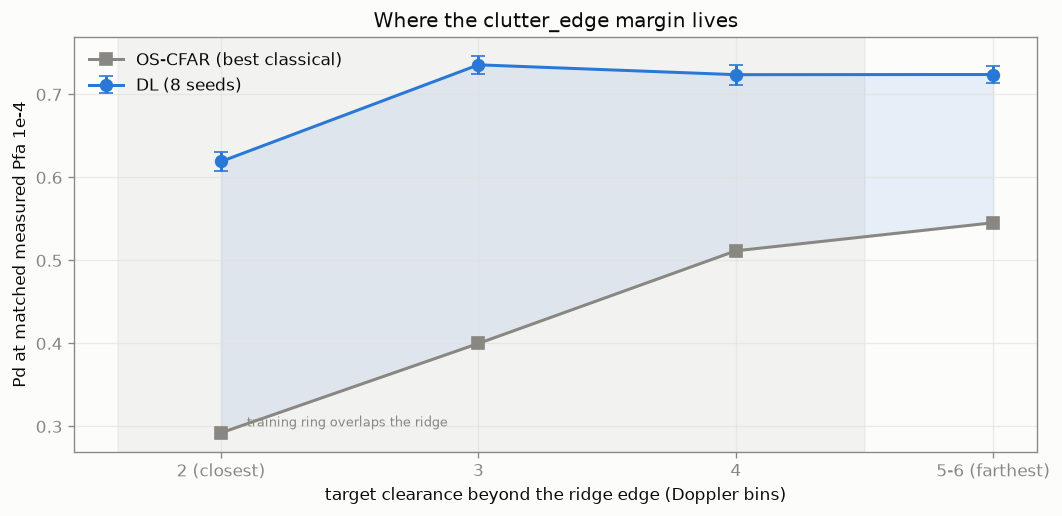

DL - best CFAR:  closest +0.327   farthest +0.114   difference +0.213
OS degrades +0.253 as the target approaches the ridge; DL degrades +0.105


In [19]:
att = DL / "clutter_edge_attribution.csv"
if att.exists():
    a = pd.read_csv(att)
    order = ["2 (closest)", "3", "4", "5-6 (farthest)"]
    dl = a[a.method == "DL"].groupby("band").pd.agg(["mean", "std", "count"]).reindex(order)
    dl["se"] = dl["std"] / np.sqrt(dl["count"])
    cf = a[a.method != "DL"].pivot_table(index="band", columns="method", values="pd").reindex(order)

    t = pd.DataFrame({"n frames": a[a.method == "CA"].set_index("band").n.reindex(order),
                      "true edge": [True, True, True, False],
                      "CA": cf.CA, "GO": cf.GO, "OS": cf.OS,
                      "best CFAR": cf.max(axis=1), "DL": dl["mean"], "DL SE": dl["se"]})
    t["DL - OS"] = t.DL - t.OS
    t["DL - best"] = t.DL - t["best CFAR"]
    display(t.round(3))

    fig, ax = plt.subplots(figsize=(9, 4.4))
    x = np.arange(len(order))
    ax.plot(x, t.OS, "s-", color=CFARC, lw=1.8, ms=7, label="OS-CFAR (best classical)")
    ax.errorbar(x, t.DL, yerr=1.96 * t["DL SE"], fmt="o-", color=DLC, lw=1.8, ms=7,
                capsize=4, label="DL (8 seeds)")
    ax.fill_between(x, t.OS, t.DL, color=DLC, alpha=0.10)
    ax.axvspan(-0.4, 2.5, color=MUTED, alpha=0.08)
    ax.text(0.1, 0.30, "training ring overlaps the ridge", fontsize=8, color=MUTED)
    ax.set_xticks(x); ax.set_xticklabels(order)
    ax.set_xlabel("target clearance beyond the ridge edge (Doppler bins)")
    ax.set_ylabel("Pd at matched measured Pfa 1e-4")
    ax.set_title("Where the clutter_edge margin lives")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

    print(f"DL - best CFAR:  closest {t['DL - best'].iloc[0]:+.3f}   farthest "
          f"{t['DL - best'].iloc[-1]:+.3f}   difference {t['DL - best'].iloc[0]-t['DL - best'].iloc[-1]:+.3f}")
    print(f"OS degrades {t.OS.iloc[-1]-t.OS.iloc[0]:+.3f} as the target approaches the ridge; "
          f"DL degrades {t.DL.iloc[-1]-t.DL.iloc[0]:+.3f}")
else:
    print("run: python scripts/attribute_clutter_edge.py")

**What it showed — H-window, supported.**

CFAR falls apart as the target approaches the ridge: OS goes 0.545 → 0.512 → 0.400 → **0.292**, a
drop of 0.253. DL is nearly flat over the same span: 0.724 → 0.724 → 0.736 → 0.619, a drop of 0.105,
and only in the closest band. That asymmetry *is* the reference-window signature — CFAR is
handicapped exactly where its training ring overlaps the ridge, and the network, having no reference
window, is not.

The margin follows: **+0.327 / +0.336 / +0.212** on the three true-edge bands against **+0.114** on
the non-edge band. That +0.114 is the same order as DL's general advantage elsewhere (isolated
+0.022, multi +0.031, masking +0.049, mixed +0.086) — so on frames that are not really edges, the
network wins by roughly its usual amount, and on genuine edges by two to three times that.

**Dilution cannot be the explanation — it works the other way.** The 28% non-edge frames carry the
*smallest* margin, so they drag the pooled figure **down**. The pooled +0.261 therefore
*understates* the true-edge effect, which is nearer +0.28 when frame-weighted.

**Strength of evidence, honestly.** The near-vs-far contrast is ~2.7σ allowing for CFAR's own
sampling error (~0.055 per band at 40–57 frames), supported by a near-monotone gradient across four
bands. Not overwhelming on the endpoint contrast alone; the gradient and the mechanism agreeing is
what makes it convincing. The two middle bands invert slightly (+0.327 vs +0.336), which is well
within that error.

**Reportable**, with the mechanism stated and the caveat that per-band counts are 40–57 frames.

### O2 — `unresolved` +0.002 is not a win
p = 0.048, but both methods sit at the ~0.5 physics cap (two targets inside one mainlobe; one
detection can match only one truth). The significance is an artefact of a very small SE (0.0008),
not a detection advantage. **Do not report as a win.**

### O3 — `pos_weight` ablation: DONE (2026-08-14), see §8
Ran at {100, 200, 974} x 8 seeds. `pos_weight` moves to **100**; 974 was the worst of the three.
The §7 clutter finding is retracted (Corrections C3).

**What this opens instead:** every §7 number was measured at 974 and is now superseded. The
headline DL-vs-CFAR table must be re-run at the chosen `pos_weight` before anything is reported, and
the `clutter_edge` attribution (§Open/O1) should be re-checked there too — its +0.261 was measured
at 974, and at 100 the same condition scores 0.731 rather than 0.704.

---
## Next experiments

Running to-do in the same per-experiment format, results blank. Fill in and move up into the
chronological list once run.

### N1 — re-run the headline comparison at `pos_weight = 100`
- **Question:** what are the per-condition mean ± SE and the DL-vs-CFAR deltas at the chosen
  hyperparameter? (§7's table is superseded; it was measured at 974.)
- **Setup:** the 8 `pw100` checkpoints already exist — this is an evaluation, not a training run.
  Re-run the `clutter_edge` attribution (§O1) at 100 as well.
- **Results / showed / changed:** *(pending)*

### N2 — `clutter_edge` attribution: true-edge vs diluted frames
- **Question:** does the +0.261 margin hold on frames where the window genuinely straddles the ridge,
  or does it come from the 34% that do not?
- **Setup:** re-run the Milestone-22 split on the 8 DL checkpoints; compare against the CFAR
  true-edge numbers already measured.
- **Results / showed / changed:** *(pending)*

### N3 — why DL loses on `clutter`
- **Question:** what does CFAR's local statistic capture inside the ridge that the network does not?
- **Setup:** per-frame comparison at matched Pfa on `clutter`; inspect frames where CFAR detects and
  DL misses; check whether the deficit concentrates at particular CNR or Weibull shape (both swept
  and recorded per frame).
- **Results / showed / changed:** *(pending)*

### N4 — final test-split evaluation
- **Question:** the reportable numbers.
- **Setup:** **only once the configuration is locked.** Seed-averaged DL vs CFAR on `bench2_test`,
  same protocol. Until then `bench2_test` stays untouched.
- **Results / showed / changed:** *(pending)*